## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [11]:
!pip install pandas
!pip install seaborn


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.3.3-cp313-cp313-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.4.9-cp313-cp313-macosx_11_0_arm64.whl.metadata (6.3 kB)
  Using cached pillow-11.3.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (9.0 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 15.3 MB/s eta 0:00:0031m15.6 MB/s eta 0:00:01
Using cached contourpy-1.3.3-cp313-cp313-macosx_11_0_arm64.whl (274 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 14.5 MB/s eta 0:00:00
Using cached kiwisolver-1.4.9-cp313-cp313-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-11.3.0-cp313-cp313-macosx_11_0_arm64.whl (4.7 MB)
   ━━━━━━━━━━

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Leer un archivo CSV
df = pd.read_csv("data/amz_uk_price_prediction_dataset.csv")

# Ver las primeras filas
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
   - Which are the top 5 most listed product categories?


In [15]:
# Crear una tabla de frecuencias para la columna "category"
frequency_table = df.category.value_counts()
proportion_table = df.category.value_counts(normalize=True).round(2)

In [17]:
frequency_table.head()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [18]:
df2 = pd.concat([frequency_table, proportion_table], axis=1)
df2.columns = ['absolute_frequency', 'relative_frequency']
df2

,absolute_frequency,relative_frequency
category,,
Sports & Outdoors,836265,0.34
Beauty,19312,0.01
"Handmade Clothing, Shoes & Accessories",19229,0.01
Bath & Body,19092,0.01
Birthday Gifts,18978,0.01
...,...,...
Alexa Built-In Devices,107,0.00
Motorbike Chassis,107,0.00
Plugs,107,0.00


In [19]:
df2 = df2.reset_index()

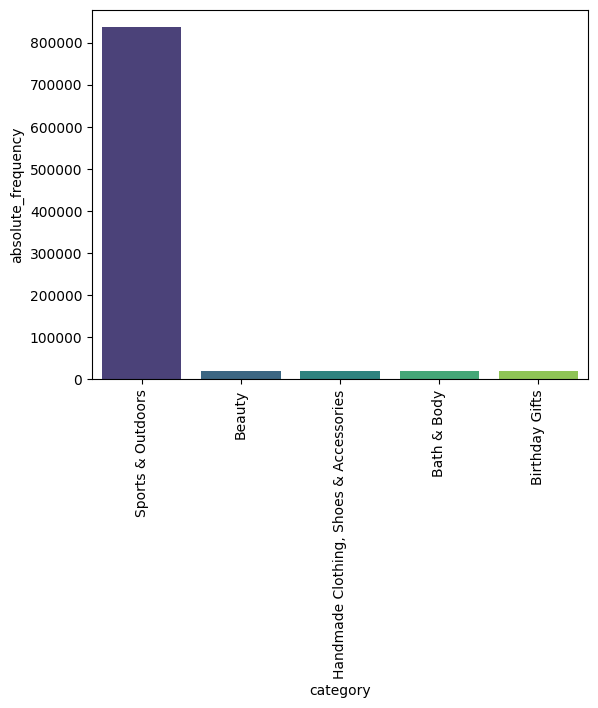

In [20]:
sns.barplot(
    x="category",
    y="absolute_frequency",
    hue="category",       # ← add this line
    data=df2.head(5),
    palette="viridis",
    legend=False          # ← optional, hide legend if not needed
)

plt.xticks(rotation=90)
plt.show()


### Pie Chart — Proportion of Top Categories

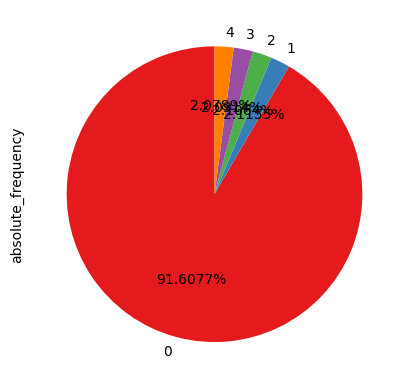

In [23]:
df2['absolute_frequency'].head(5).plot.pie(autopct='%1.4f%%' ,startangle=90, colors=sns.color_palette('Set1'))
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [27]:
# Suppose your DataFrame is called df and has a 'price' column
# --- Medidas de Centralidad para la variable 'price' ---
price_stats = df['price'].describe()
mean_price = price_stats['mean']
median_price = price_stats['50%']
mode_price = df['price'].mode()[0]

print("Descripción estadística general de 'price':")
print(price_stats)
print("Medidas Centrality :")
print(f"Media (mean): {mean_price:.2f}")
print(f"Mediana (median): {median_price:.2f}")
print(f"Moda (mode): {mode_price:.2f}")



Descripción estadística general de 'price':
count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64
Medidas Centrality :
Media (mean): 89.24
Mediana (median): 19.09
Moda (mode): 9.99


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [29]:

# Basic measures of dispersion
variance = df["price"].var()
std_dev = df["price"].std()
price_range = df["price"].max() - df["price"].min()

# Interquartile Range (IQR)
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
iqr = Q3 - Q1

print(f"Variance: {variance:.2f}")
print(f"Standard Deviation: {std_dev:.2f}")
print(f"Range: {price_range:.2f}")
print(f"IQR (Interquartile Range): {iqr:.2f}")


Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.00
IQR (Interquartile Range): 36.00


### it show a high variability in the prices

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

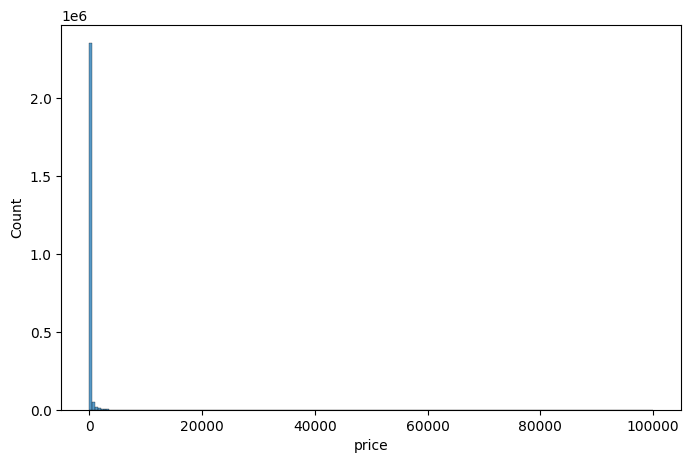

In [59]:
plt.figure(figsize=(8,5))
sns.histplot(df["price"], bins=200)
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?




In [37]:
### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [44]:
stars_stats = df['stars'].describe()
mean_stars = stars_stats['mean']
median_stars = stars_stats['50%']
mode_stars = df['stars'].mode()[0]

print("Descripción general de 'stars':")
print(stars_stats)
print(" Medidas de centralidad:")
print(f"Media (mean): {mean_stars:.2f}")
print(f"Mediana (median): {median_stars:.2f}")

Descripción general de 'stars':
count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64
 Medidas de centralidad:
Media (mean): 2.15
Mediana (median): 0.00


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [38]:
# --- Medidas de dispersión ---
variance_stars = df["stars"].var()
std_stars = df["stars"].std()
Q1_stars = df["stars"].quantile(0.25)
Q3_stars = df["stars"].quantile(0.75)
iqr_stars = Q3_stars - Q1_stars

print(f"Variance: {variance_stars:.4f}")
print(f"Standard Deviation: {std_stars:.4f}")
print(f"IQR (Interquartile Range): {iqr_stars:.2f}")


Variance: 4.8174
Standard Deviation: 2.1949
IQR (Interquartile Range): 4.40



3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [45]:
# --- Forma de la distribución ---
skewness = df['stars'].skew()
kurtosis = df['stars'].kurt()

print(f"Skewness (Asimetría): {skewness:.3f}")
print(f"Kurtosis (Curtosis): {kurtosis:.3f}")


Skewness (Asimetría): 0.081
Kurtosis (Curtosis): -1.926




4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

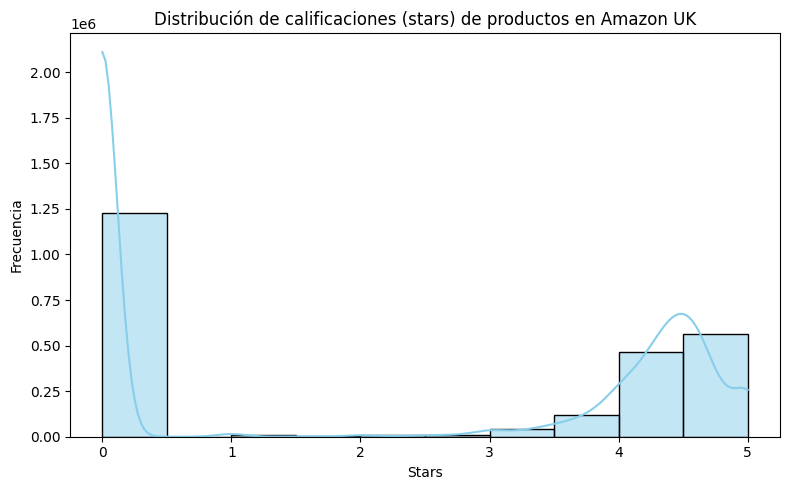

In [46]:

plt.figure(figsize=(8,5))
sns.histplot(df['stars'], bins=10, kde=True, color='skyblue')
plt.title("Distribución de calificaciones (stars) de productos en Amazon UK")
plt.xlabel("Stars")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()